# TP : analyse des accidents de la route avec PySpark

On refait l'analyse du notebook *Big data Analysis of Road Crash Data using PySpark* (Rakesh Nain) : on étudie les accidents de la route en Australie-Méridionale entre 2012 et 2019 avec Spark, en utilisant les trois façons de manipuler des données dans Spark : les RDD, les DataFrames et Spark SQL.

## 1. Les données

Les données viennent du Department of Planning, Transport and Infrastructure (DPTI) d'Australie-Méridionale et sont publiées sur https://data.sa.gov.au. On utilise deux jeux de données, avec un fichier CSV par année :

- **Crash** : une ligne par accident (lieu, date, heure, type d'accident, gravité, nombre de victimes, présence d'alcool ou de drogue...).
- **Units** : une ligne par « unité » impliquée dans un accident, c'est-à-dire un véhicule ou un piéton (type de véhicule, sexe et âge du conducteur, permis...).

Les deux sont reliés par la colonne `REPORT_ID`. Le jour exact de l'accident n'est pas publié (donnée sensible) : on a seulement l'année, le mois et le jour de la semaine, donc on affichera les dates au format `Année-Mois-Jour`, par exemple `2017-January-Sunday`.

La description de chaque colonne est dans le fichier `metadata-for-road-crash.pdf` du dépôt GitHub de l'auteur.

## 2. Installation

Comme pour le comptage de mots avec Spark : PySpark s'installe avec pip, et Spark 4 a besoin de Java 17 qu'on télécharge dans le dossier personnel. On installe aussi pandas et matplotlib pour les graphiques.

Les commandes d'installation sont prévues pour Linux (Google Colab, ou WSL sous Windows).

In [1]:
%pip install -q pyspark pandas matplotlib

In [2]:
import os

HOME = os.path.expanduser("~")
os.environ["JAVA_HOME"] = HOME + "/jdk17"
os.environ["PATH"] = HOME + "/jdk17/bin:" + os.environ["PATH"]

if not os.path.exists(HOME + "/jdk17/bin/java"):
    !mkdir -p ~/jdk17
    !wget -qO- "https://api.adoptium.net/v3/binary/latest/17/ga/linux/x64/jdk/hotspot/normal/eclipse" | tar -xz -C ~/jdk17 --strip-components=1

!java -version

openjdk version "17.0.16" 2025-07-15
OpenJDK Runtime Environment Temurin-17.0.16+8 (build 17.0.16+8)
OpenJDK 64-Bit Server VM Temurin-17.0.16+8 (build 17.0.16+8, mixed mode, sharing)


On télécharge les 16 fichiers CSV (8 années × 2 jeux de données) depuis le dépôt GitHub de l'auteur, s'ils ne sont pas déjà dans le dossier.

In [3]:
import urllib.request

BASE = "https://raw.githubusercontent.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/main"

for dossier, jeu in [("crash_data", "Crash"), ("units_data", "Units")]:
    os.makedirs(dossier, exist_ok=True)
    for annee in range(2012, 2020):
        nom = f"{annee}_DATA_SA_{jeu}.csv"
        chemin = os.path.join(dossier, nom)
        if not os.path.exists(chemin):
            urllib.request.urlretrieve(f"{BASE}/{dossier}/{nom}", chemin)

!ls -lh crash_data units_data

crash_data:
total 41M
-rw-r--r-- 1 etudiant etudiant 7.2M Oct 16 10:12 2012_DATA_SA_Crash.csv
-rw-r--r-- 1 etudiant etudiant 5.3M Oct 16 10:12 2013_DATA_SA_Crash.csv
-rw-r--r-- 1 etudiant etudiant 5.2M Oct 16 10:12 2014_DATA_SA_Crash.csv
-rw-r--r-- 1 etudiant etudiant 4.9M Oct 16 10:12 2015_DATA_SA_Crash.csv
-rw-r--r-- 1 etudiant etudiant 5.4M Oct 16 10:12 2016_DATA_SA_Crash.csv
-rw-r--r-- 1 etudiant etudiant 4.2M Oct 16 10:12 2017_DATA_SA_Crash.csv
-rw-r--r-- 1 etudiant etudiant 4.3M Oct 16 10:12 2018_DATA_SA_Crash.csv
-rw-r--r-- 1 etudiant etudiant 4.1M Oct 16 10:12 2019_DATA_SA_Crash.csv

units_data:
total 36M
-rw-r--r-- 1 etudiant etudiant 6.4M Oct 16 10:12 2012_DATA_SA_Units.csv
-rw-r--r-- 1 etudiant etudiant 4.7M Oct 16 10:12 2013_DATA_SA_Units.csv
-rw-r--r-- 1 etudiant etudiant 4.6M Oct 16 10:12 2014_DATA_SA_Units.csv
-rw-r--r-- 1 etudiant etudiant 4.4M Oct 16 10:12 2015_DATA_SA_Units.csv
-rw-r--r-- 1 etudiant etudiant 4.7M Oct 16 10:12 2016_DATA_SA_Units.csv
-rw-r--r-- 1 etudia

## 3. Démarrage de Spark

Ici on fait du **calcul parallèle** et pas du **calcul distribué** : le travail est réparti entre les cœurs d'une seule machine, alors qu'en distribué il serait réparti entre plusieurs machines d'un cluster. Pour Spark, c'est presque la même chose : il traite les cœurs comme des machines, et pour passer sur un vrai cluster il suffirait de changer l'adresse du `master`, le reste du code ne change pas.

La configuration se fait avec un objet `SparkConf` :
- `local[*]` : Spark tourne en local avec autant de threads que de cœurs logiques (`local[4]` pour en utiliser 4) ;
- `appName` : le nom de l'application, affiché dans l'interface web de Spark.

On crée ensuite une `SparkSession`, le point d'entrée pour les DataFrames et Spark SQL. Elle contient un `SparkContext` (`sc`), qui sert à créer les RDD.

In [4]:
from pyspark import SparkConf
from pyspark.sql import SparkSession
from pyspark.rdd import RDD
from pyspark.sql.functions import col
import pyspark.sql.functions as F
import csv
import time
from functools import reduce
import pandas as pd
import matplotlib.pyplot as plt

conf = (SparkConf()
        .setMaster("local[*]")
        .setAppName("Analyse des accidents de la route")
        .set("spark.ui.showConsoleProgress", "false"))

spark = SparkSession.builder.config(conf=conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel("ERROR")

print("Version de Spark :", spark.version)
print("Nombre de cœurs utilisés :", sc.defaultParallelism)

Version de Spark : 4.2.0
Nombre de cœurs utilisés : 8


## 4. Analyse avec les RDD

Un RDD (*Resilient Distributed Dataset*) est la structure de base de Spark : c'est une collection d'objets Python, non modifiable, découpée en **partitions**. Chaque partition est traitée par un cœur (ou une machine sur un cluster), c'est ce qui permet le calcul en parallèle. Si une partition est perdue, Spark sait la recalculer à partir des opérations qui l'ont créée, d'où le « Resilient ».

Comme vu dans le TP sur le comptage de mots, il y a deux types d'opérations :
- les **transformations** (`map`, `filter`, `reduceByKey`...) créent un nouveau RDD mais ne calculent rien tout de suite ;
- les **actions** (`collect`, `count`, `take`...) lancent vraiment le calcul et renvoient un résultat au programme Python.

On peut créer un RDD de deux façons avec le `SparkContext` :
- `parallelize()` à partir d'une collection Python (liste, tuple, ensemble) ;
- `textFile()` à partir d'un fichier texte.

### Création d'un RDD avec `parallelize()`

In [5]:
donnees = list(range(10))

rdd = sc.parallelize(donnees)
print("Partitions par défaut :", rdd.getNumPartitions())

# on peut choisir le nombre de partitions avec le 2e argument
rdd = sc.parallelize(donnees, 5)
print("Partitions choisies :", rdd.getNumPartitions())
print("Contenu de chaque partition :", rdd.glom().collect())

Partitions par défaut : 8
Partitions choisies : 5
Contenu de chaque partition : [[0, 1], [2, 3], [4, 5], [6, 7], [8, 9]]


Par défaut, Spark crée une partition par cœur. Avec 5 partitions, les 10 nombres sont répartis 2 par 2 : `glom()` regroupe les éléments de chaque partition dans une liste, ce qui permet de voir le découpage.

### Chargement des fichiers avec `textFile()`

Avec `textFile()`, chaque ligne du fichier devient un élément du RDD (une chaîne de caractères). Le `*` dans le chemin permet de charger les 8 fichiers d'un coup dans un seul RDD.

Chaque fichier commence par une ligne d'en-tête avec le nom des colonnes. On la récupère avec `first()` puis on enlève toutes les lignes qui lui sont égales : comme les 8 fichiers ont le même en-tête, ça enlève les 8 en-têtes d'un coup.

In [6]:
units_rdd = sc.textFile("units_data/*.csv")
crash_rdd = sc.textFile("crash_data/*.csv")

units_header = units_rdd.first()
units_rdd = units_rdd.filter(lambda ligne: ligne != units_header)

crash_header = crash_rdd.first()
crash_rdd = crash_rdd.filter(lambda ligne: ligne != crash_header)

print("Nombre d'unités :", units_rdd.count())
print("Nombre d'accidents :", crash_rdd.count())
print()
print(units_header)
for ligne in units_rdd.take(3):
    print(ligne)
print()
print(crash_header)
for ligne in crash_rdd.take(3):
    print(ligne)

Nombre d'unités : 272591
Nombre d'accidents : 127672

"REPORT_ID","Unit No","No Of Cas","Veh Reg State","Unit Type","Veh Year","Direction Of Travel","Sex","Age","Lic State","Licence Class","Licence Type","Towing","Unit Movement","Number Occupants","Postcode","Rollover","Fire"
"2012-1-21/08/2019","01",0,,"Pedal Cycle",,"South West","Male","035",,,,,"Straight Ahead","001","5074",,
"2012-1-21/08/2019","02",0,"SA","Motor Cars - Sedan","2009","North West","Female","050","SA","C ","Full","Unknown","Leaving Private Driveway","001","5089",,
"2012-2-21/08/2019","01",0,"SA","Motor Cars - Sedan","1999","West","Male","027","SA",,"Provisional 1 ","Not Towing","Straight Ahead","002","5008",,

"REPORT_ID","Stats Area","Suburb","Postcode","LGA Name","Total Units","Total Cas","Total Fats","Total SI","Total MI","Year","Month","Day","Time","Area Speed","Position Type","Horizontal Align","Vertical Align","Other Feat","Road Surface","Moisture Cond","Weather Cond","DayNight","Crash Type","Unit Resp","Entity

On a 127 672 accidents et 272 591 unités, donc un peu plus de 2 unités par accident en moyenne, ce qui est logique (la plupart des accidents impliquent deux véhicules). Pour l'instant chaque élément du RDD est juste une ligne de texte brute.

In [7]:
print("Partitions de units_rdd :", units_rdd.getNumPartitions())
print("Partitions de crash_rdd :", crash_rdd.getNumPartitions())

Partitions de units_rdd : 8
Partitions de crash_rdd : 8


On n'a pas choisi de partitionnement, donc Spark découpe les données lui-même. Ici on obtient 8 partitions, une par fichier : chaque fichier ne fait que quelques Mo, donc Spark n'a pas besoin de les couper en morceaux (comme avec Hadoop, où un fichier plus petit qu'un bloc de 128 Mo n'était traité que par un seul mapper).

### Découpage des lignes CSV

Pour exploiter les lignes, il faut les découper en colonnes. Le notebook d'origine utilise `ligne.split(',')`, mais ça pose un problème : certaines valeurs contiennent elles-mêmes une virgule, entre guillemets. Par exemple dès le premier accident, la commune est `"CC OF NORWOOD,PAYNEHAM & ST PETERS"`. Avec `split(',')`, cette valeur est coupée en deux et toutes les colonnes suivantes sont décalées d'un cran.

On utilise donc le module `csv` de Python, qui gère correctement les guillemets.

In [8]:
def lire_ligne(ligne):
    return next(csv.reader([ligne]))


exemple = crash_rdd.first()
print("Colonnes dans l'en-tête :", len(lire_ligne(crash_header)))
print("Colonnes avec split(',') :", len(exemple.split(",")))
print("Colonnes avec le module csv :", len(lire_ligne(exemple)))

print("Lignes d'accident mal découpées par split :",
      crash_rdd.filter(lambda l: len(l.split(",")) != len(lire_ligne(l))).count())
print("Lignes d'unité mal découpées par split :",
      units_rdd.filter(lambda l: len(l.split(",")) != len(lire_ligne(l))).count())

Colonnes dans l'en-tête : 33
Colonnes avec split(',') : 34
Colonnes avec le module csv : 33
Lignes d'accident mal découpées par split : 21379
Lignes d'unité mal découpées par split : 0


Plus de 21 000 lignes d'accident seraient mal découpées avec `split(',')`. Pour les unités il n'y a aucun problème, c'est pour ça que les requêtes sur les unités du notebook d'origine donnent quand même le bon résultat.

Pour ne pas avoir à retenir les numéros des colonnes, on crée un dictionnaire nom de colonne → index à partir de l'en-tête. On garde aussi les RDD découpés en mémoire avec `cache()`, car on va les réutiliser dans toutes les requêtes : sans ça, Spark relirait et redécouperait les fichiers à chaque action.

In [9]:
U = {nom: i for i, nom in enumerate(lire_ligne(units_header))}
C = {nom: i for i, nom in enumerate(lire_ligne(crash_header))}
print("Colonnes de Units :", list(U))
print("Colonnes de Crash :", list(C))

units_lignes = units_rdd.map(lire_ligne).cache()
crash_lignes = crash_rdd.map(lire_ligne).cache()

Colonnes de Units : ['REPORT_ID', 'Unit No', 'No Of Cas', 'Veh Reg State', 'Unit Type', 'Veh Year', 'Direction Of Travel', 'Sex', 'Age', 'Lic State', 'Licence Class', 'Licence Type', 'Towing', 'Unit Movement', 'Number Occupants', 'Postcode', 'Rollover', 'Fire']
Colonnes de Crash : ['REPORT_ID', 'Stats Area', 'Suburb', 'Postcode', 'LGA Name', 'Total Units', 'Total Cas', 'Total Fats', 'Total SI', 'Total MI', 'Year', 'Month', 'Day', 'Time', 'Area Speed', 'Position Type', 'Horizontal Align', 'Vertical Align', 'Other Feat', 'Road Surface', 'Moisture Cond', 'Weather Cond', 'DayNight', 'Crash Type', 'Unit Resp', 'Entity Code', 'CSEF Severity', 'Traffic Ctrls', 'DUI Involved', 'Drugs Involved', 'ACCLOC_X', 'ACCLOC_Y', 'UNIQUE_LOC']


### Partitionnement personnalisé

On peut aussi choisir nous-mêmes comment répartir les données. Comme dans le notebook d'origine, on fait deux partitions : une pour les véhicules immatriculés en Australie-Méridionale (`SA`) et une pour tous les autres. On utilise la colonne `Veh Reg State`, l'état d'immatriculation du véhicule (le notebook d'origine l'appelle « Lic State », mais c'est bien la 4e colonne, `Veh Reg State`, qu'il utilise).

Pour ça il faut un RDD de paires (clé, valeur) : la clé est l'état d'immatriculation et la valeur est le reste de la ligne. `partitionBy` prend le nombre de partitions et une fonction qui donne le numéro de partition pour chaque clé.

In [10]:
def separer_etat(l):
    i = U["Veh Reg State"]
    return (l[i], l[:i] + l[i + 1:])


units_etat_rdd = units_lignes.map(separer_etat)


def partition_sa(cle):
    if cle == "SA":
        return 0
    return 1


sa_rdd = units_etat_rdd.partitionBy(2, partition_sa)


def afficher_partitions(donnees):
    if not isinstance(donnees, RDD):
        donnees = donnees.rdd
    print("Nombre de partitions :", donnees.getNumPartitions())
    for i, taille in enumerate(donnees.glom().map(len).collect()):
        print(f"Partition {i} : {taille} lignes")


afficher_partitions(sa_rdd)

Nombre de partitions : 2
Partition 0 : 218366 lignes
Partition 1 : 54225 lignes


80 % des unités sont des véhicules immatriculés en Australie-Méridionale, ce qui est normal puisque ce sont les accidents de cet état. Les 20 % restants sont surtout des unités sans immatriculation (piétons, vélos) ou inconnues.

Les deux partitions sont donc très déséquilibrées : un cœur aurait 4 fois plus de travail que l'autre. Dans la pratique on partitionne par une clé quand on va ensuite faire des regroupements ou des jointures sur cette clé (les lignes de même clé sont déjà au même endroit, donc moins d'échanges entre les cœurs), mais il faut faire attention à l'équilibre des partitions.

Dans `afficher_partitions`, on compte la taille de chaque partition avec `glom().map(len)` plutôt que de faire `glom().collect()` comme dans l'original : comme ça on ne rapatrie que 2 nombres au lieu de toutes les lignes.

### Requête 1 : âge moyen des conducteurs selon le sexe

Il faut enlever les lignes où l'âge est inconnu (vide ou `XXX`) et où le sexe n'est pas renseigné. On utilise `flatMap` avec une fonction qui renvoie une liste vide pour les lignes à ignorer : ça permet de filtrer et transformer en une seule étape.

Pour la moyenne, on calcule pour chaque sexe la somme des âges et le nombre de personnes avec `reduceByKey`. Le notebook d'origine utilise `groupByKey`, qui envoie tous les âges de chaque sexe au même endroit avant de faire la moyenne. `reduceByKey` fait déjà les sommes dans chaque partition avant d'échanger les données (comme le combiner de Hadoop), donc beaucoup moins de données circulent.

In [11]:
def sexe_age(l):
    sexe, age = l[U["Sex"]], l[U["Age"]]
    if sexe in ("Male", "Female") and age not in ("", "XXX"):
        return [(sexe, (int(age), 1))]
    return []


age_moyen = (units_lignes.flatMap(sexe_age)
             .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
             .mapValues(lambda s: round(s[0] / s[1], 2)))
age_moyen.collect()

[('Male', 40.8), ('Female', 40.08)]

L'âge moyen des personnes impliquées dans un accident est presque le même pour les hommes (40,8 ans) et pour les femmes (40,1 ans). On retrouve les mêmes valeurs que dans le notebook d'origine.

### Requête 2 : véhicules les plus anciens et les plus récents

On affiche l'état d'immatriculation et le type des véhicules avec l'année de fabrication la plus ancienne et la plus récente. On enlève les années inconnues (vide ou `XXXX`), puis on trie avec `sortByKey`, l'année étant la clé.

Pour afficher les 5 premiers, on utilise `take(5)` et pas `collect()[0:5]` comme dans l'original : `collect()` ramène les 230 000 lignes dans le programme Python pour n'en garder que 5, alors que `take(5)` ne ramène que ce qui est demandé.

In [12]:
def annee_vehicule(l):
    annee = l[U["Veh Year"]]
    if annee not in ("", "XXXX"):
        return [(int(annee), (l[U["Veh Reg State"]], l[U["Unit Type"]]))]
    return []


annees_rdd = units_lignes.flatMap(annee_vehicule)

print("Les 5 véhicules les plus anciens :")
for v in annees_rdd.sortByKey(ascending=True).take(5):
    print(v)
print()
print("Les 5 véhicules les plus récents :")
for v in annees_rdd.sortByKey(ascending=False).take(5):
    print(v)

Les 5 véhicules les plus anciens :
(1900, ('VIC', 'Motor Cycle'))
(1900, ('SA', 'Motor Cycle'))
(1900, ('SA', 'Motor Cycle'))
(1900, ('SA', 'Motor Cycle'))
(1900, ('SA', 'Motor Cycle'))

Les 5 véhicules les plus récents :
(2019, ('SA', 'Station Wagon'))
(2019, ('SA', 'OMNIBUS'))
(2019, ('SA', 'Motor Cars - Sedan'))
(2019, ('SA', 'Station Wagon'))
(2019, ('SA', 'SEMI TRAILER'))


Les véhicules les plus récents sont de 2019, ce qui est cohérent puisque les données s'arrêtent en 2019. Par contre, les plus anciens sont de 1900 : 14 véhicules ont cette année-là alors que l'année suivante dans les données est 1924. C'est sûrement une valeur mise par défaut quand l'année n'est pas connue, il faudrait donc la traiter comme une valeur manquante pour une vraie analyse.

## 5. Analyse avec les DataFrames

Un DataFrame est une collection de données distribuée organisée en colonnes nommées, comme une table SQL ou un DataFrame pandas, mais découpée en partitions comme un RDD. La différence avec un RDD, c'est que Spark connaît le **schéma** (le nom et le type de chaque colonne) : il peut donc optimiser le plan de calcul avant de l'exécuter, et faire les calculs directement dans la JVM sans passer par des fonctions Python. C'est en général plus rapide, et plus court à écrire.

On peut créer un DataFrame à partir d'une liste avec `createDataFrame` :

In [13]:
df = spark.createDataFrame([(1, "Alice", "A"), (2, "Bastien", "B"), (3, "Chloé", "C"),
                            (4, "David", "D"), (5, "Emma", "E"), (6, "Farid", "F")],
                           ["Id", "Nom", "Initiale"])
df.show(5)
df.printSchema()

+---+-------+--------+
| Id|    Nom|Initiale|
+---+-------+--------+
|  1|  Alice|       A|
|  2|Bastien|       B|
|  3|  Chloé|       C|
|  4|  David|       D|
|  5|   Emma|       E|
+---+-------+--------+
only showing top 5 rows
root
 |-- Id: long (nullable = true)
 |-- Nom: string (nullable = true)
 |-- Initiale: string (nullable = true)



Pour les accidents, on lit directement les fichiers CSV avec `spark.read`. L'option `header` indique que la première ligne contient le nom des colonnes, et `escape` indique comment sont échappés les guillemets à l'intérieur d'une valeur. Contrairement à notre `split(',')`, le lecteur CSV de Spark gère les virgules entre guillemets.

Par défaut toutes les colonnes sont lues comme du texte. On convertit donc en entier les colonnes de victimes dont on va avoir besoin pour faire des sommes et des tris (`Total Cas` : nombre total de victimes, `Total Fats` : morts, `Total SI` : blessés graves, `Total MI` : blessés légers). Sans ça, un tri sur `Total Cas` serait un tri alphabétique (« 9 » passerait devant « 10 »).

In [14]:
units_df = spark.read.option("header", True).option("escape", '"').csv("units_data/*.csv")
crash_df = spark.read.option("header", True).option("escape", '"').csv("crash_data/*.csv")

for colonne in ["Total Cas", "Total Fats", "Total SI", "Total MI"]:
    crash_df = crash_df.withColumn(colonne, col(colonne).cast("int"))

print("Nombre d'unités :", units_df.count())
print("Nombre d'accidents :", crash_df.count())
crash_df.printSchema()

Nombre d'unités : 272591
Nombre d'accidents : 127672
root
 |-- REPORT_ID: string (nullable = true)
 |-- Stats Area: string (nullable = true)
 |-- Suburb: string (nullable = true)
 |-- Postcode: string (nullable = true)
 |-- LGA Name: string (nullable = true)
 |-- Total Units: string (nullable = true)
 |-- Total Cas: integer (nullable = true)
 |-- Total Fats: integer (nullable = true)
 |-- Total SI: integer (nullable = true)
 |-- Total MI: integer (nullable = true)
 |-- Year: string (nullable = true)
 |-- Month: string (nullable = true)
 |-- Day: string (nullable = true)
 |-- Time: string (nullable = true)
 |-- Area Speed: string (nullable = true)
 |-- Position Type: string (nullable = true)
 |-- Horizontal Align: string (nullable = true)
 |-- Vertical Align: string (nullable = true)
 |-- Other Feat: string (nullable = true)
 |-- Road Surface: string (nullable = true)
 |-- Moisture Cond: string (nullable = true)
 |-- Weather Cond: string (nullable = true)
 |-- DayNight: string (nullable

On retrouve bien le même nombre de lignes qu'avec les RDD.

### Requête 1 : accidents à Adélaïde avec plus de 3 victimes

On ne garde que quelques colonnes pour que le tableau reste lisible (le notebook d'origine affiche les 33 colonnes avec `collect()`).

In [15]:
adelaide_df = crash_df.filter((col("Total Cas") > 3) & (col("Suburb") == "ADELAIDE"))

print("Nombre d'accidents :", adelaide_df.count())
adelaide_df.select("REPORT_ID", "Year", "Month", "Day", "Time", "Crash Type",
                   "Total Cas", "Total Fats", "Total SI", "Total MI").show(truncate=False)

Nombre d'accidents : 6
+---------------------+----+--------+--------+--------+--------------+---------+----------+--------+--------+
|REPORT_ID            |Year|Month   |Day     |Time    |Crash Type    |Total Cas|Total Fats|Total SI|Total MI|
+---------------------+----+--------+--------+--------+--------------+---------+----------+--------+--------+
|2012-4842-21/08/2019 |2012|March   |Thursday|04:00 pm|Rear End      |4        |0         |0       |4       |
|2012-5769-21/08/2019 |2012|March   |Friday  |09:30 am|Right Angle   |4        |0         |0       |4       |
|2017-1613-15/08/2019 |2017|February|Saturday|04:00 pm|Right Turn    |4        |0         |0       |4       |
|2017-12182-15/08/2019|2017|December|Saturday|04:08 pm|Hit Pedestrian|5        |0         |1       |4       |
|2018-601-17/01/2020  |2018|January |Sunday  |09:12 pm|Hit Pedestrian|4        |0         |2       |2       |
|2019-10404-8/07/2020 |2019|October |Monday  |08:20 am|Right Turn    |6        |0         |0     

Il n'y a que 6 accidents avec plus de 3 victimes dans le centre d'Adélaïde en 8 ans, et aucun mort. Ce sont surtout des blessés légers (`Total MI`) : en ville la vitesse est limitée à 50 km/h, donc les accidents sont moins graves. Les seuls blessés graves (`Total SI`) sont dans les deux accidents où un piéton a été renversé.

### Requête 2 : les 10 accidents avec le plus de victimes

In [16]:
(crash_df.orderBy(col("Total Cas").desc())
 .select("REPORT_ID", "Suburb", "Year", "Month", "Crash Type", "Area Speed",
         "Total Units", "Total Cas", "Total Fats", "Total SI", "Total MI")
 .show(10, truncate=False))

+---------------------+-------------+----+--------+-----------+----------+-----------+---------+----------+--------+--------+
|REPORT_ID            |Suburb       |Year|Month   |Crash Type |Area Speed|Total Units|Total Cas|Total Fats|Total SI|Total MI|
+---------------------+-------------+----+--------+-----------+----------+-----------+---------+----------+--------+--------+
|2017-288-15/08/2019  |PARA HILLS   |2017|January |Right Angle|060       |2          |11       |0         |1       |10      |
|2014-9004-21/08/2019 |APY          |2014|July    |Roll Over  |100       |2          |9        |1         |0       |8       |
|2014-14065-21/08/2019|MODBURY NORTH|2014|November|Rear End   |040       |5          |9        |0         |0       |9       |
|2016-3035-15/08/2019 |HACKHAM      |2016|January |Right Turn |080       |3          |9        |3         |5       |1       |
|2016-6630-15/08/2019 |KANGAROO FLAT|2016|April   |Head On    |100       |3          |9        |0         |2       |7 

L'accident avec le plus de victimes en a fait 11 (une collision à angle droit à Para Hills, presque que des blessés légers). On voit deux types d'accidents dans ce top 10 :
- en ville (limite à 40 ou 60 km/h), avec beaucoup de blessés mais surtout légers, par exemple le carambolage de 5 véhicules à Modbury North ;
- sur les routes de campagne (100 ou 110 km/h), avec des tonneaux (`Roll Over`) et des collisions frontales (`Head On`) : là il y a des morts et des blessés graves, comme à Merriton avec 4 morts.

La vitesse joue donc beaucoup sur la gravité, pas seulement sur le nombre de victimes.

### Requête 3 : nombre de morts par type d'accident

In [17]:
(crash_df.groupBy("Crash Type")
 .agg(F.sum("Total Fats").alias("Total morts"))
 .orderBy(col("Total morts").desc())
 .show(truncate=False))

+--------------------------+-----------+
|Crash Type                |Total morts|
+--------------------------+-----------+
|Hit Fixed Object          |245        |
|Head On                   |136        |
|Hit Pedestrian            |109        |
|Roll Over                 |93         |
|Right Angle               |82         |
|Rear End                  |33         |
|Side Swipe                |30         |
|Right Turn                |26         |
|Hit Parked Vehicle        |10         |
|Hit Animal                |7          |
|Other                     |5          |
|Left Road - Out of Control|3          |
|Hit Object on Road        |2          |
+--------------------------+-----------+


Les accidents les plus mortels sont les sorties de route contre un obstacle fixe (arbre, poteau...), avec 245 morts, devant les collisions frontales (136) et les piétons renversés (109). Les accidents par l'arrière (`Rear End`) sont très fréquents mais font peu de morts, car ils arrivent souvent à faible vitesse.

Comme on a converti `Total Fats` en entier, on obtient des nombres entiers (dans l'original la colonne était restée en texte et Spark affichait des réels comme `245.0`).

### Requête 4 : victimes par quartier quand le conducteur n'a pas de permis

Le type de permis est dans le jeu Units et le quartier dans le jeu Crash, il faut donc faire une **jointure** sur `REPORT_ID`. En écrivant `on="REPORT_ID"`, la colonne n'apparaît qu'une fois dans le résultat (avec `crash_df.REPORT_ID == units_df.REPORT_ID` comme dans l'original, on aurait deux colonnes `REPORT_ID`).

Ensuite on garde les unités dont le type de permis est `Unlicenced` et on additionne le nombre de victimes des accidents pour chaque quartier.

In [18]:
complet_df = crash_df.join(units_df, on="REPORT_ID", how="inner")

sans_permis_df = (complet_df.filter(col("Licence Type") == "Unlicenced")
                  .groupBy("Suburb")
                  .agg(F.sum("Total Cas").alias("Total victimes"))
                  .orderBy(col("Total victimes").desc(), "Suburb"))
sans_permis_df.show(10)

+--------------+--------------+
|        Suburb|Total victimes|
+--------------+--------------+
|      ADELAIDE|            43|
|     SALISBURY|            30|
|      PROSPECT|            27|
|    INGLE FARM|            22|
| MORPHETT VALE|            20|
|SALISBURY EAST|            20|
|     DRY CREEK|            19|
| MURRAY BRIDGE|            19|
|  MAWSON LAKES|            17|
|NORTH ADELAIDE|            17|
+--------------+--------------+
only showing top 10 rows


Le centre d'Adélaïde arrive en premier avec 43 victimes, suivi de plusieurs quartiers du nord de l'agglomération (Salisbury, Prospect, Ingle Farm...).

Remarque : si deux conducteurs sans permis sont impliqués dans le même accident, les victimes de cet accident sont comptées deux fois, car la jointure crée une ligne par unité. C'est rare, et on garde le même calcul que le notebook d'origine.

### Gravité des accidents selon l'alcool et la drogue

La colonne `CSEF Severity` donne la gravité de l'accident, sur 4 niveaux (d'après les métadonnées) :
- `1: PDO` (*Property Damage Only*) : dégâts matériels seulement ;
- `2: MI` (*Minor Injury*) : blessés légers ;
- `3: SI` (*Serious Injury*) : blessés graves ;
- `4: Fatal` : au moins un mort.

Les colonnes `DUI Involved` et `Drugs Involved` valent `Y` si un conducteur a été contrôlé positif à l'alcool ou à la drogue, et sont vides sinon (Spark les lit comme `null`). On peut donc regarder si les accidents sont plus graves quand il y a de l'alcool ou de la drogue.

On commence par le nombre d'accidents pour chaque niveau de gravité :

In [19]:
crash_df.groupBy("CSEF Severity").agg(F.count("*").alias("Nb accidents")).orderBy("CSEF Severity").show()

+-------------+------------+
|CSEF Severity|Nb accidents|
+-------------+------------+
|       1: PDO|       84775|
|        2: MI|       37300|
|        3: SI|        4875|
|     4: Fatal|         722|
+-------------+------------+


La grande majorité des accidents ne fait que des dégâts matériels (84 775 sur 127 672, soit 66 %), et 722 accidents ont été mortels.

On veut maintenant la même répartition, en nombre et en pourcentage, pour 4 cas :
- a) conducteur positif à la drogue ;
- b) conducteur positif à l'alcool ;
- c) positif aux deux ;
- d) négatif aux deux.

Le notebook d'origine recopie le même code 4 fois, avec à chaque fois une UDF (une fonction Python appliquée par Spark à chaque ligne) pour calculer le pourcentage. On fait plutôt une seule fonction qu'on appelle 4 fois, et on calcule le pourcentage avec les fonctions de Spark (`F.round`, opérations sur les colonnes). C'est plus rapide qu'une UDF, car avec une UDF chaque valeur doit être envoyée de la JVM vers Python puis renvoyée.

In [20]:
def repartition_gravite(df):
    total = df.count()
    return (df.groupBy("CSEF Severity")
            .agg(F.count("*").alias("Nb accidents"))
            .withColumn("Pourcentage", F.round(col("Nb accidents") * 100 / total, 2))
            .orderBy("CSEF Severity"))


drogue = col("Drugs Involved") == "Y"
alcool = col("DUI Involved") == "Y"

scenarios = {
    "a) Drogue": crash_df.filter(drogue),
    "b) Alcool": crash_df.filter(alcool),
    "c) Drogue et alcool": crash_df.filter(drogue & alcool),
    "d) Ni drogue ni alcool": crash_df.filter(col("Drugs Involved").isNull() & col("DUI Involved").isNull()),
}

for nom, df in scenarios.items():
    print(nom)
    repartition_gravite(df).show()

a) Drogue
+-------------+------------+-----------+
|CSEF Severity|Nb accidents|Pourcentage|
+-------------+------------+-----------+
|       1: PDO|         237|      12.78|
|        2: MI|        1109|      59.82|
|        3: SI|         391|      21.09|
|     4: Fatal|         117|       6.31|
+-------------+------------+-----------+

b) Alcool
+-------------+------------+-----------+
|CSEF Severity|Nb accidents|Pourcentage|
+-------------+------------+-----------+
|       1: PDO|        2144|      53.88|
|        2: MI|        1243|      31.24|
|        3: SI|         456|      11.46|
|     4: Fatal|         136|       3.42|
+-------------+------------+-----------+

c) Drogue et alcool
+-------------+------------+-----------+
|CSEF Severity|Nb accidents|Pourcentage|
+-------------+------------+-----------+
|       1: PDO|          36|      12.08|
|        2: MI|         151|      50.67|
|        3: SI|          72|      24.16|
|     4: Fatal|          39|      13.09|
+-------------+

On regroupe les 4 cas dans un seul tableau, avec une colonne par cas, en faisant une jointure sur `CSEF Severity` (`reduce` permet d'enchaîner les jointures des 4 tableaux).

In [21]:
noms_courts = ["Drogue", "Alcool", "Les deux", "Aucun"]

tables_nb = []
tables_pct = []
for nom, df in zip(noms_courts, scenarios.values()):
    rep = repartition_gravite(df)
    tables_nb.append(rep.select("CSEF Severity", col("Nb accidents").alias(nom)))
    tables_pct.append(rep.select("CSEF Severity", col("Pourcentage").alias(nom)))

nb_df = reduce(lambda a, b: a.join(b, on="CSEF Severity"), tables_nb).orderBy("CSEF Severity")
pct_df = reduce(lambda a, b: a.join(b, on="CSEF Severity"), tables_pct).orderBy("CSEF Severity")

print("Nombre d'accidents :")
nb_df.show()
print("Pourcentage des accidents de chaque cas :")
pct_df.show()

Nombre d'accidents :
+-------------+------+------+--------+-----+
|CSEF Severity|Drogue|Alcool|Les deux|Aucun|
+-------------+------+------+--------+-----+
|       1: PDO|   237|  2144|      36|82430|
|        2: MI|  1109|  1243|     151|35099|
|        3: SI|   391|   456|      72| 4100|
|     4: Fatal|   117|   136|      39|  508|
+-------------+------+------+--------+-----+

Pourcentage des accidents de chaque cas :
+-------------+------+------+--------+-----+
|CSEF Severity|Drogue|Alcool|Les deux|Aucun|
+-------------+------+------+--------+-----+
|       1: PDO| 12.78| 53.88|   12.08|67.49|
|        2: MI| 59.82| 31.24|   50.67|28.74|
|        3: SI| 21.09| 11.46|   24.16| 3.36|
|     4: Fatal|  6.31|  3.42|   13.09| 0.42|
+-------------+------+------+--------+-----+


La différence est très nette :
- sans alcool ni drogue, seulement 0,42 % des accidents sont mortels et 67 % ne font que des dégâts matériels ;
- avec de l'alcool, 3,4 % des accidents sont mortels, soit 8 fois plus ;
- avec de la drogue, 6,3 % sont mortels et seulement 13 % ne font que des dégâts matériels ;
- avec les deux, 13 % des accidents sont mortels, soit 30 fois plus que sans rien.

Il faut quand même faire attention à l'interprétation : on ne voit que les accidents où un test a été fait et est revenu positif. Les tests (surtout de drogue, qui demandent une prise de sang) sont sans doute plus systématiques après un accident grave qu'après un simple accrochage, ce qui augmente forcément la part d'accidents graves dans les cas positifs. Mais l'écart est tellement grand qu'il montre bien que l'alcool et la drogue rendent les accidents plus graves.

### Graphiques

Spark n'a pas d'outil pour faire des graphiques. On convertit donc les résultats en DataFrame pandas avec `toPandas()`, puis on utilise matplotlib.

`toPandas()` ramène toutes les données dans la mémoire du programme Python, sur une seule machine, sans parallélisme. Ici ce n'est pas un problème car les tableaux n'ont que 4 lignes, mais sur un vrai gros DataFrame ça pourrait saturer la mémoire. Il faut donc toujours faire les calculs lourds (filtres, regroupements) avec Spark, et ne convertir que le petit résultat final, ou un échantillon des données (avec `sample()`).

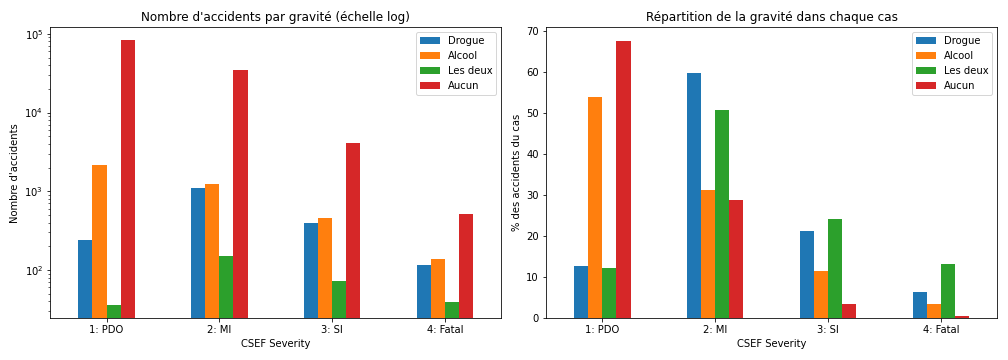

In [22]:
nb_pd = nb_df.toPandas().set_index("CSEF Severity")
pct_pd = pct_df.toPandas().set_index("CSEF Severity")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

nb_pd.plot(kind="bar", ax=axes[0], logy=True, rot=0)
axes[0].set_title("Nombre d'accidents par gravité (échelle log)")
axes[0].set_ylabel("Nombre d'accidents")

pct_pd.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Répartition de la gravité dans chaque cas")
axes[1].set_ylabel("% des accidents du cas")

plt.tight_layout()
plt.show()

Pour le nombre d'accidents, on utilise une échelle logarithmique : sinon le cas « Aucun » (plus de 82 000 accidents en dégâts matériels) écrase complètement les autres barres. Ce graphique montre surtout que les accidents avec alcool ou drogue sont peu nombreux par rapport au total.

Le graphique des pourcentages est plus intéressant : on voit que la barre « Dégâts matériels » (`1: PDO`) est très haute pour « Aucun » et « Alcool », alors que pour « Drogue » et « Les deux » ce sont les blessés légers qui dominent et la part de blessés graves et de morts est bien plus élevée.

## 6. Mêmes requêtes avec les RDD, les DataFrames et Spark SQL

On peut écrire les mêmes requêtes avec les trois outils. Pour Spark SQL, on enregistre les DataFrames comme des tables temporaires avec `createOrReplaceTempView`, puis on écrit une requête SQL classique avec `spark.sql`. Les noms de colonnes qui contiennent des espaces doivent être entre accents graves (`` `Total Cas` ``).

Spark SQL et les DataFrames utilisent le même moteur : une requête SQL est transformée dans le même plan de calcul que le code DataFrame équivalent.

In [23]:
units_df.createOrReplaceTempView("units")
crash_df.createOrReplaceTempView("crash")

Pour vérifier que les trois méthodes donnent le même résultat, on transforme chaque résultat en liste triée de tuples. Une valeur manquante est une chaîne vide dans le RDD (on a juste découpé le texte) et `None` dans un DataFrame, donc on remplace les `None` par des chaînes vides avant de comparer.

In [24]:
def normaliser(lignes):
    return sorted(tuple("" if v is None else v for v in ligne) for ligne in lignes)

### Requête A : détails des accidents à Adélaïde

Pour chaque unité impliquée dans un accident à Adélaïde, on affiche la date et l'heure de l'accident, le nombre de victimes, et le sexe, l'âge et le type de permis du conducteur.

**Avec les RDD** : on transforme les deux RDD en paires (`REPORT_ID`, ligne), puis `join` regroupe les lignes qui ont la même clé et donne des éléments de la forme (`REPORT_ID`, (accident, unité)). On filtre les accidents d'Adélaïde **avant** la jointure : il y a beaucoup moins de lignes à échanger entre les partitions.

Dans le notebook d'origine, cette version donnait de mauvaises colonnes (l'âge à la place du sexe, l'état du permis à la place de l'âge...). En plus du problème de `split(',')`, la clé avait été enlevée de la ligne, donc tous les index étaient décalés de 1. Utiliser les noms des colonnes avec les dictionnaires `U` et `C` évite ce genre d'erreur.

In [25]:
def details(paire):
    accident, unite = paire[1]
    date = accident[C["Year"]] + "-" + accident[C["Month"]] + "-" + accident[C["Day"]]
    return (date, accident[C["Time"]], int(accident[C["Total Cas"]]),
            unite[U["Sex"]], unite[U["Age"]], unite[U["Licence Type"]], accident[C["Suburb"]])


crash_adelaide_rdd = (crash_lignes.filter(lambda l: l[C["Suburb"]] == "ADELAIDE")
                      .map(lambda l: (l[C["REPORT_ID"]], l)))
units_par_id_rdd = units_lignes.map(lambda l: (l[U["REPORT_ID"]], l))

resultat_rdd = crash_adelaide_rdd.join(units_par_id_rdd).map(details).collect()

print("Nombre de lignes :", len(resultat_rdd))
for ligne in sorted(resultat_rdd)[:5]:
    print(ligne)

Nombre de lignes : 11965
('2012-April-Friday', '01:00 am', 0, 'Male', '026', 'Full', 'ADELAIDE')
('2012-April-Friday', '01:00 am', 0, 'Male', '028', '', 'ADELAIDE')
('2012-April-Friday', '01:00 pm', 0, '', '', '', 'ADELAIDE')
('2012-April-Friday', '01:00 pm', 0, 'Unknown', 'XXX', 'Unknown', 'ADELAIDE')
('2012-April-Friday', '01:30 pm', 0, 'Male', '024', 'Unlicenced', 'ADELAIDE')


**Avec un DataFrame** : on reprend la jointure `complet_df`, et on construit la date avec `concat_ws` qui colle plusieurs colonnes avec un séparateur (l'original utilise une UDF pour ça).

In [26]:
adelaide_details_df = (complet_df.filter(col("Suburb") == "ADELAIDE")
                       .select(F.concat_ws("-", "Year", "Month", "Day").alias("Date"),
                               "Time", "Total Cas", "Sex", "Age", "Licence Type", "Suburb"))
adelaide_details_df.show(5)
resultat_df = adelaide_details_df.collect()

+-------------------+--------+---------+------+---+-------------+--------+
|               Date|    Time|Total Cas|   Sex|Age| Licence Type|  Suburb|
+-------------------+--------+---------+------+---+-------------+--------+
|2012-January-Monday|08:45 am|        0|  Male|084|         Full|ADELAIDE|
|2012-January-Monday|08:45 am|        0|  Male|040|         Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|  Male|047|         Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|  Male|XXX|         NULL|ADELAIDE|
|2012-January-Friday|07:30 pm|        1|Female|018|Provisional 2|ADELAIDE|
+-------------------+--------+---------+------+---+-------------+--------+
only showing top 5 rows


**Avec Spark SQL** : `||` sert à concaténer des chaînes.

In [27]:
adelaide_details_sql = spark.sql('''
    SELECT c.Year || '-' || c.Month || '-' || c.Day AS Date,
           c.Time, c.`Total Cas`, u.Sex, u.Age, u.`Licence Type`, c.Suburb
    FROM crash c JOIN units u ON c.REPORT_ID = u.REPORT_ID
    WHERE c.Suburb = 'ADELAIDE'
''')
adelaide_details_sql.show(5)
resultat_sql = adelaide_details_sql.collect()

+-------------------+--------+---------+------+---+-------------+--------+
|               Date|    Time|Total Cas|   Sex|Age| Licence Type|  Suburb|
+-------------------+--------+---------+------+---+-------------+--------+
|2012-January-Monday|08:45 am|        0|  Male|084|         Full|ADELAIDE|
|2012-January-Monday|08:45 am|        0|  Male|040|         Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|  Male|047|         Full|ADELAIDE|
|2012-January-Friday|05:45 pm|        0|  Male|XXX|         NULL|ADELAIDE|
|2012-January-Friday|07:30 pm|        1|Female|018|Provisional 2|ADELAIDE|
+-------------------+--------+---------+------+---+-------------+--------+
only showing top 5 rows


In [28]:
print("Nombre de lignes : RDD =", len(resultat_rdd), "| DataFrame =", len(resultat_df), "| SQL =", len(resultat_sql))
print("RDD = DataFrame :", normaliser(resultat_rdd) == normaliser(resultat_df))
print("DataFrame = SQL :", normaliser(resultat_df) == normaliser(resultat_sql))

Nombre de lignes : RDD = 11965 | DataFrame = 11965 | SQL = 11965
RDD = DataFrame : True
DataFrame = SQL : True


Les trois méthodes donnent exactement les mêmes lignes. Certaines lignes ont un âge `XXX` ou un sexe vide : ce sont des unités sans conducteur connu (véhicule garé, conducteur en fuite...).

### Requête B : victimes par quartier quand le conducteur n'a pas de permis

C'est la même question que la requête 4 de la partie 5. Dans la dernière partie du notebook d'origine, les trois versions de cette requête ne gardent pas les conducteurs sans permis : elles enlèvent les permis inconnus, donc elles gardent surtout les conducteurs **avec** permis, et la version DataFrame compte des lignes au lieu d'additionner les victimes. On refait donc la requête correctement, en gardant les unités dont le type de permis est `Unlicenced` et en additionnant `Total Cas`.

On mesure aussi le temps de chaque méthode.

**Avec les RDD** :

In [29]:
debut = time.time()

units_sans_permis_rdd = (units_lignes.filter(lambda l: l[U["Licence Type"]] == "Unlicenced")
                         .map(lambda l: (l[U["REPORT_ID"]], 1)))
crash_victimes_rdd = crash_lignes.map(lambda l: (l[C["REPORT_ID"]], (l[C["Suburb"]], int(l[C["Total Cas"]]))))

victimes_rdd = (units_sans_permis_rdd.join(crash_victimes_rdd)    # (id, (1, (quartier, victimes)))
                .map(lambda paire: paire[1][1])                    # (quartier, victimes)
                .reduceByKey(lambda a, b: a + b)
                .collect())

temps_rdd = time.time() - debut

for ligne in sorted(victimes_rdd, key=lambda x: (-x[1], x[0]))[:10]:
    print(ligne)

('ADELAIDE', 43)
('SALISBURY', 30)
('PROSPECT', 27)
('INGLE FARM', 22)
('MORPHETT VALE', 20)
('SALISBURY EAST', 20)
('DRY CREEK', 19)
('MURRAY BRIDGE', 19)
('MAWSON LAKES', 17)
('NORTH ADELAIDE', 17)


**Avec un DataFrame** (même code que la requête 4) :

In [30]:
debut = time.time()
victimes_df = (complet_df.filter(col("Licence Type") == "Unlicenced")
               .groupBy("Suburb")
               .agg(F.sum("Total Cas").alias("Total victimes"))
               .collect())
temps_df = time.time() - debut

for ligne in sorted(victimes_df, key=lambda x: (-x[1], x[0]))[:10]:
    print(ligne)

Row(Suburb='ADELAIDE', Total victimes=43)
Row(Suburb='SALISBURY', Total victimes=30)
Row(Suburb='PROSPECT', Total victimes=27)
Row(Suburb='INGLE FARM', Total victimes=22)
Row(Suburb='MORPHETT VALE', Total victimes=20)
Row(Suburb='SALISBURY EAST', Total victimes=20)
Row(Suburb='DRY CREEK', Total victimes=19)
Row(Suburb='MURRAY BRIDGE', Total victimes=19)
Row(Suburb='MAWSON LAKES', Total victimes=17)
Row(Suburb='NORTH ADELAIDE', Total victimes=17)


**Avec Spark SQL** :

In [31]:
debut = time.time()
victimes_sql = spark.sql('''
    SELECT c.Suburb, SUM(c.`Total Cas`) AS `Total victimes`
    FROM crash c JOIN units u ON c.REPORT_ID = u.REPORT_ID
    WHERE u.`Licence Type` = 'Unlicenced'
    GROUP BY c.Suburb
''').collect()
temps_sql = time.time() - debut

for ligne in sorted(victimes_sql, key=lambda x: (-x[1], x[0]))[:10]:
    print(ligne)

Row(Suburb='ADELAIDE', Total victimes=43)
Row(Suburb='SALISBURY', Total victimes=30)
Row(Suburb='PROSPECT', Total victimes=27)
Row(Suburb='INGLE FARM', Total victimes=22)
Row(Suburb='MORPHETT VALE', Total victimes=20)
Row(Suburb='SALISBURY EAST', Total victimes=20)
Row(Suburb='DRY CREEK', Total victimes=19)
Row(Suburb='MURRAY BRIDGE', Total victimes=19)
Row(Suburb='MAWSON LAKES', Total victimes=17)
Row(Suburb='NORTH ADELAIDE', Total victimes=17)


In [32]:
print("RDD = DataFrame :", normaliser(victimes_rdd) == normaliser(victimes_df))
print("DataFrame = SQL :", normaliser(victimes_df) == normaliser(victimes_sql))
print()
print(f"Temps RDD       : {temps_rdd:.2f} s")
print(f"Temps DataFrame : {temps_df:.2f} s")
print(f"Temps SQL       : {temps_sql:.2f} s")

RDD = DataFrame : True
DataFrame = SQL : True

Temps RDD       : 2.84 s
Temps DataFrame : 1.12 s
Temps SQL       : 1.05 s


Les trois méthodes donnent le même résultat, et c'est le même que celui de la requête 4 (43 victimes pour le centre d'Adélaïde).

Les versions DataFrame et SQL sont plus rapides que la version RDD, alors que la version RDD travaille sur des données déjà découpées et gardées en mémoire avec `cache()`. Avec les RDD, chaque `lambda` est une fonction Python : Spark doit envoyer les données de la JVM vers des processus Python, puis récupérer le résultat. Avec les DataFrames et SQL, Spark connaît les opérations à faire et les exécute directement dans la JVM, après avoir optimisé le plan (par exemple en ne lisant que les colonnes utiles). Les temps de DataFrame et SQL sont proches, car c'est le même moteur derrière.

## 7. Conclusion

On a refait la même analyse avec les trois outils de Spark :
- les **RDD** sont les plus souples, car on manipule directement des objets Python, mais il faut tout faire à la main : découper les lignes, retrouver les colonnes par leur numéro, gérer les valeurs manquantes. C'est là que le notebook d'origine faisait des erreurs (`split(',')` qui décale les colonnes, index décalés après la jointure) ;
- les **DataFrames** et **Spark SQL** connaissent le schéma des données, le code est plus court et plus lisible, et Spark peut optimiser les calculs, ce qui les rend plus rapides.

Côté analyse, les accidents les plus mortels sont les sorties de route contre un obstacle et les collisions frontales, et la présence d'alcool ou de drogue est associée à des accidents beaucoup plus graves (13 % d'accidents mortels quand le conducteur est positif aux deux, contre 0,4 % sinon).

Avec 130 000 accidents (77 Mo de CSV), les données tiennent largement sur une seule machine, mais le même code fonctionnerait sans changement sur un cluster avec des volumes beaucoup plus gros.

## 8. Arrêt de Spark

In [33]:
spark.stop()